# Load libraries

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_percentage_error
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy import stats

print("all imports ok")

all imports ok


# Load data

In [45]:
# ======================================
# 2. Load Monthly Data
# ======================================

# Define the folder where the source CSV is stored
base_path = r"C:\Users\theodorakisa\OneDrive - AIA\Desktop\Angelos\Projects\Forecasting\Passenger Forecast"

# Define the full path of the CSV file
file_path = base_path + r"\Passenger_monthly_data.csv"


# Read monthly passenger data
df = pd.read_csv(file_path, sep=";")
df.head()

# change type 
df["Grand Total"] = (
    df["Grand Total"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .astype(int)
)

# Create date column from Year + Month
df["Date"] = pd.to_datetime(
    df["Year"].astype(str) + "-" + df["Month"],
    format="%Y-%B"
)

# Sort chronologically
df = df.sort_values("Date").reset_index(drop=True)

# Create dataset used for forecasting
monthly = df[["Date", "Grand Total"]].copy()

# Rename columns
monthly.columns = ["Date", "Passengers"]

print("\nFirst 5 rows:")
print(monthly.head())

print("\nLast 5 rows:")
print(monthly.tail())



First 5 rows:
        Date  Passengers
0 2019-01-01     1392885
1 2019-02-01     1327788
2 2019-03-01     1652594
3 2019-04-01     1986756
4 2019-05-01     2285206

Last 5 rows:
         Date  Passengers
89 2026-06-01     3514324
90 2026-07-01     3932400
91 2026-08-01     4027701
92 2026-09-01     3599857
93 2026-10-01     3210367


# Visualize Historical Data

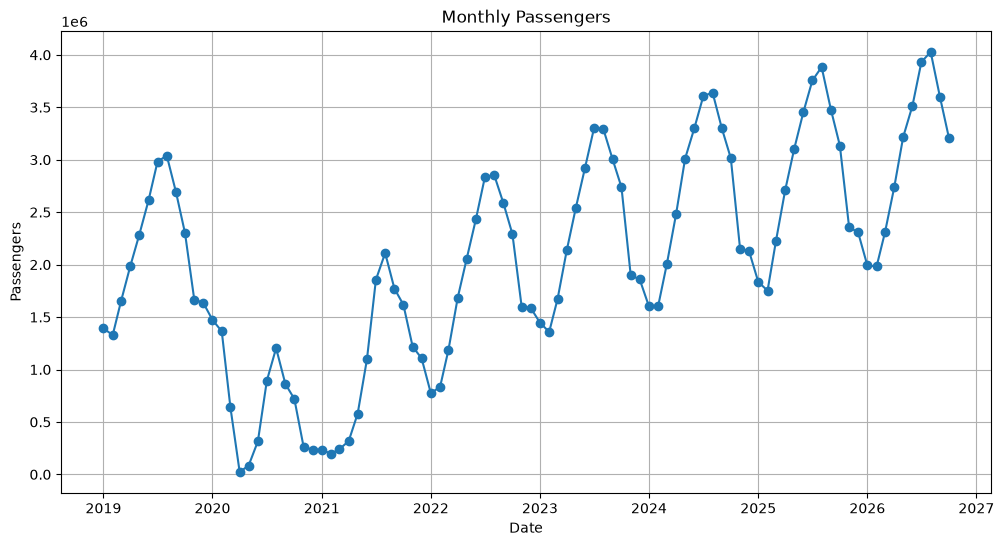

In [46]:
# Plot monthly passenger evolution
plt.figure(figsize=(12,6))

plt.plot(
    monthly["Date"],
    monthly["Passengers"],
    marker="o"
)

# Formatting
plt.title("Monthly Passengers")
plt.xlabel("Date")
plt.ylabel("Passengers")
plt.grid(True)

# Show chart
plt.show()